# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Zahwa Annisa Hendajani
- **Email:** zahwannisa444@gmail.com
- **ID Dicoding:** DS009B6X1813

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau metrik yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Kategori produk apa saja yang menyumbang total pendapatan (revenue) tertinggi dan terendah sepanjang tahun 2017?
    * Keterangan:
        * Specific: Fokus mencari kategori produk dengan pendapatan terbesar dan terkecil, bukan sekadar jumlah barang yang terjual.
        * Measurable: Pendapatan dapat dihitung secara konkret menggunakan total dari kolom price pada data item pesanan.
        * Action-Oriented: Tim bisnis dapat mengalokasikan anggaran marketing yang lebih besar untuk kategori pemenang (tertinggi), atau mengevaluasi ulang strategi ketersediaan stok untuk kategori terbawah.
        * Relevant: Pendapatan (revenue) adalah metrik krusial dalam keberhasilan e-commerce.
        * Time-bound: Analisis dibatasi khusus pada pesanan di tahun 2017.

- **Pertanyaan 2:** Bagaimana hubungan lama waktu pengiriman (selisih hari dari pesanan dibayar hingga sampai ke pelanggan) terhadap skor ulasan (review score) yang diberikan pelanggan selama periode 2017-2018?
    * Keterangan:
        * Specific: Menyelidiki korelasi langsung antara durasi pengiriman dengan metrik kepuasan (review score).
        * Measurable: Waktu pengiriman bisa dihitung dalam satuan hari (dari kolom timestamp pesanan), dan skor ulasan memiliki rentang angka 1 hingga 5.
        * Action-Oriented: Jika ditemukan hubungan antara pengiriman lambat dan skor yang lebih rendah, perusahaan bisa mendesak mitra logistik untuk menetapkan SLA (Service Level Agreement) yang lebih ketat atau mengganti vendor pengiriman.
        * Relevant: Kepuasan pelanggan sangat berdampak pada retensi dan reputasi e-commerce.
        * Time-bound: Menggunakan data historis pesanan dari tahun 2017 hingga 2018.

## Import Semua Packages/Library yang Digunakan

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt

## Data Wrangling

### Gathering Data

#### Load dataset yang dibutuhkan

In [15]:
# Memuat data orders dan order_items
orders_df = pd.read_csv("orders_dataset.csv")
order_items_df = pd.read_csv("order_items_dataset.csv")

# Memuat data produk dan terjemahan nama kategori produk (ke bahasa Inggris)
products_df = pd.read_csv("products_dataset.csv")
product_category_df = pd.read_csv("product_category_name_translation.csv")

# Memuat data ulasan pelanggan (reviews)
reviews_df = pd.read_csv("order_reviews_dataset.csv")

# Menampilkan cuplikan salah satu data untuk memastikan berhasil dimuat
orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


**Insight:** (Opsional)
- Seluruh dataset yang diperlukan untuk menjawab pertanyaan bisnis (`orders_dataset.csv`, `order_items_dataset.csv`, `products_dataset.csv`, `product_category_name_translation.csv`, dan `order_reviews_dataset.csv`) berhasil dimuat ke dalam format pandas DataFrame tanpa kendala.
- Berdasarkan pratinjau `orders_df.head()`, tabel pesanan mencatat setiap tahapan waktu transaksi secara mendetail—mulai dari waktu pembelian (`order_purchase_timestamp`), persetujuan pembayaran (`order_approved_at`), penyerahan ke kurir, hingga estimasi dan waktu aktual pesanan diterima pelanggan—yang sangat relevan untuk menghitung durasi pengiriman pada Pertanyaan Bisnis 2.
- Data transaksi yang ditampilkan mencakup rentang waktu lintas tahun (terlihat sampel transaksi dari tahun 2017 dan 2018), sehingga kita perlu melakukan penyaringan (filtering) tahun secara spesifik pada tahap analisis agar sesuai dengan batasan waktu pada masing-masing pertanyaan bisnis.

### Assessing Data

#### Identifying missing value problem

In [16]:
# 1. Menilai tabel orders
print("Info dataset orders:")
print(orders_df.info())
print("\nJumlah missing values di orders:")
print(orders_df.isna().sum())

print("-" * 50)

# 2. Menilai tabel reviews
print("\nInfo dataset reviews:")
print(reviews_df.info())
print("\nJumlah missing values di reviews:")
print(reviews_df.isna().sum())

Info dataset orders:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB
None

Jumlah missing values di orders:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delive

#### Identifying duplicated data problem

In [17]:
print("Jumlah duplikasi di orders:", orders_df.duplicated().sum())
print("Jumlah duplikasi di order_items:", order_items_df.duplicated().sum())
print("Jumlah duplikasi di products:", products_df.duplicated().sum())
print("Jumlah duplikasi di reviews:", reviews_df.duplicated().sum())

Jumlah duplikasi di orders: 0
Jumlah duplikasi di order_items: 0
Jumlah duplikasi di products: 0
Jumlah duplikasi di reviews: 0


#### Identifying outlier problem

In [18]:
print("Ringkasan statistik order_items (cek kolom price):")
print(order_items_df[["price", "freight_value"]].describe())

# Mengidentifikasi outlier harga dengan metode IQR.
q1 = order_items_df["price"].quantile(0.25)
q3 = order_items_df["price"].quantile(0.75)
iqr = q3 - q1
lower_bound = max(0, q1 - 1.5 * iqr)
upper_bound = q3 + 1.5 * iqr
price_outliers = order_items_df[
    (order_items_df["price"] < lower_bound)
    | (order_items_df["price"] > upper_bound)
]
print(f"Batas outlier harga: {lower_bound:.2f} sampai {upper_bound:.2f}")
print(f"Jumlah outlier harga berdasarkan IQR: {len(price_outliers)}")

Ringkasan statistik order_items (cek kolom price):
               price  freight_value
count  112650.000000  112650.000000
mean      120.653739      19.990320
std       183.633928      15.806405
min         0.850000       0.000000
25%        39.900000      13.080000
50%        74.990000      16.260000
75%       134.900000      21.150000
max      6735.000000     409.680000
Batas outlier harga: 0.00 sampai 277.40
Jumlah outlier harga berdasarkan IQR: 8427


**Steps to Take:**
- Menangani Missing Value: Menghapus (drop) baris pada `orders_df` yang memiliki nilai kosong pada kolom tanggal pengiriman (`order_approved_at` dan `order_delivered_customer_date`) karena kedua kolom tersebut krusial untuk menghitung durasi pengiriman pada Pertanyaan Bisnis 2. Untuk kolom komentar yang kosong pada `reviews_df`, akan dilakukan imputasi dengan teks "No Comment" agar baris skor ulasannya tetap dapat digunakan.
- Memperbaiki Tipe Data: Mengonversi seluruh kolom tanggal/waktu pada `orders_df` (`order_purchase_timestamp`, `order_approved_at`, `order_delivered_carrier_date`, `order_delivered_customer_date`, `order_estimated_delivery_date`) dan `reviews_df` (`review_creation_date`, `review_answer_timestamp`) ke format datetime menggunakan `pd.to_datetime()`

**Insight:** (Opsional)
- Pada tabel `orders_df` (99.441 baris), ditemukan missing value pada kolom `order_approved_at` (160 baris), `order_delivered_carrier_date` (1.783 baris), dan `order_delivered_customer_date` (2.965 baris) — kemungkinan besar berasal dari pesanan yang dibatalkan atau masih dalam proses pengiriman.
- Pada tabel `reviews_df` (99.224 baris), terdapat missing value yang cukup besar pada kolom teks ulasan, yakni `review_comment_title` (87.656 baris) dan `review_comment_message` (58.247 baris), sementara kolom `review_score` terisi lengkap tanpa nilai kosong.
- Seluruh kolom tanggal dan waktu pada kedua tabel tersebut masih terbaca dengan tipe data object (string), bukan datetime.
- Tidak ditemukan satupun baris data duplikat (0) di seluruh tabel utama (`orders`, `order_items`, `products`, dan `reviews`), sehingga integritas keunikan baris sudah terjaga.
- Dari 112.650 item pesanan, harga produk (`price`) memiliki nilai minimum 0,85, median (50%) sebesar 74,99, dan nilai maksimum mencapai 6.735,00. Nilai maksimum tersebut dipertahankan karena masih positif dan dapat merepresentasikan produk bernilai tinggi; outlier statistik tidak otomatis berarti data tidak valid.

### Cleaning Data

#### Fixing missing value & inaccurate data type problems

In [19]:
# 1. Membersihkan dataset orders
# Menghapus baris yang memiliki missing value pada kolom tanggal penting
orders_before_cleaning = len(orders_df)
orders_df.dropna(
    subset=[
        'order_approved_at',
        'order_delivered_carrier_date',
        'order_delivered_customer_date'
    ],
    inplace=True
)
print(f"Baris orders sebelum cleaning: {orders_before_cleaning}")
print(f"Baris orders setelah cleaning: {len(orders_df)}")

# Mengubah tipe data kolom tanggal di orders_df menjadi datetime
datetime_columns_orders = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]
for col in datetime_columns_orders:
    orders_df[col] = pd.to_datetime(orders_df[col])

# 2. Membersihkan dataset reviews
# Mengisi missing value pada kolom komentar dengan "No Comment"
reviews_df.fillna({'review_comment_title': 'No Comment', 'review_comment_message': 'No Comment'}, inplace=True)

# Mengubah tipe data kolom tanggal di reviews_df menjadi datetime
datetime_columns_reviews = ['review_creation_date', 'review_answer_timestamp']
for col in datetime_columns_reviews:
    reviews_df[col] = pd.to_datetime(reviews_df[col])

# 3. Membersihkan dataset products & menggabungkan terjemahan nama kategori
# Menghapus produk yang tidak memiliki nama kategori, lalu merge dengan tabel translasi
products_df.dropna(subset=['product_category_name'], inplace=True)
products_df = pd.merge(
    left=products_df,
    right=product_category_df,
    how='left',
    on='product_category_name'
)

# Mengisi kategori yang belum memiliki terjemahan bahasa Inggris dengan nama aslinya
products_df['product_category_name_english'] = products_df['product_category_name_english'].fillna(products_df['product_category_name'])

# Verifikasi hasil cleaning
print("Sisa missing value di orders_df:\n", orders_df.isna().sum())
print("\nSisa missing value di reviews_df:\n", reviews_df.isna().sum())
print("\nTipe data orders_df terbaru:\n", orders_df.dtypes)

Baris orders sebelum cleaning: 99441
Baris orders setelah cleaning: 96461
Sisa missing value di orders_df:
 order_id                         0
customer_id                      0
order_status                     0
order_purchase_timestamp         0
order_approved_at                0
order_delivered_carrier_date     0
order_delivered_customer_date    0
order_estimated_delivery_date    0
dtype: int64

Sisa missing value di reviews_df:
 review_id                  0
order_id                   0
review_score               0
review_comment_title       0
review_comment_message     0
review_creation_date       0
review_answer_timestamp    0
dtype: int64

Tipe data orders_df terbaru:
 order_id                                 object
customer_id                              object
order_status                             object
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_dat

**Insight:** (Opsional)
- Seluruh baris dengan *missing value* pada kolom tanggal pengiriman di `orders_df` telah berhasil dihapus sehingga tidak ada lagi nilai kosong (0), dan seluruh kolom waktu pada `orders_df` maupun `reviews_df` kini sudah berformat `datetime64[ns]`.
- Nilai kosong pada kolom judul dan isi ulasan di `reviews_df` telah terimputasi menjadi `"No Comment"`, mempertahankan seluruh data skor ulasan (`review_score`) untuk kebutuhan analisis kepuasan pelanggan.
- Tabel `products_df` telah dibersihkan dari kategori kosong dan digabungkan dengan `product_category_df` sehingga nama kategori produk kini tersedia dalam bahasa Inggris (`product_category_name_english`) agar lebih informatif saat analisis dan visualisasi.

## Exploratory Data Analysis (EDA)

### Explore Pendapatan Kategori Produk Tahun 2017

In [20]:
# Menggabungkan orders_df, order_items_df, dan products_df
orders_items_df = pd.merge(
    left=orders_df,
    right=order_items_df,
    how='inner',
    on='order_id'
)

full_products_orders_df = pd.merge(
    left=orders_items_df,
    right=products_df,
    how='inner',
    on='product_id'
)

# Filter pesanan khusus tahun 2017 dan berstatus 'delivered'
orders_2017_df = full_products_orders_df[
    (full_products_orders_df['order_purchase_timestamp'].dt.year == 2017) &
    (full_products_orders_df['order_status'] == 'delivered')
]

# Menghitung total revenue (price) dan jumlah item terjual per kategori produk
category_revenue_2017 = orders_2017_df.groupby(by='product_category_name_english').agg({
    'order_id': 'nunique',
    'order_item_id': 'count',
    'price': 'sum'
}).reset_index()

category_revenue_2017.rename(columns={
    'product_category_name_english': 'category',
    'order_id': 'total_orders',
    'order_item_id': 'total_items_sold',
    'price': 'total_revenue'
}, inplace=True)

# Urutkan dari revenue tertinggi ke terendah
category_revenue_2017 = category_revenue_2017.sort_values(by='total_revenue', ascending=False)

print("Top 5 Kategori Produk dengan Revenue Tertinggi (2017):")
print(category_revenue_2017.head(5))

print("\nBottom 5 Kategori Produk dengan Revenue Terendah (2017):")
print(category_revenue_2017.tail(5))

Top 5 Kategori Produk dengan Revenue Tertinggi (2017):
                 category  total_orders  total_items_sold  total_revenue
7          bed_bath_table          4422              5134      490462.93
71          watches_gifts          2073              2227      475610.71
43          health_beauty          3305              3581      473833.00
66         sports_leisure          3537              3975      435426.16
15  computers_accessories          2546              3010      391786.29

Bottom 5 Kategori Produk dengan Revenue Terendah (2017):
                     category  total_orders  total_items_sold  total_revenue
29  fashion_childrens_clothes             4                 4         349.98
62      security_and_services             2                 2         283.29
35                    flowers             8                 8         270.50
3       arts_and_craftmanship             2                 2         151.89
23        diapers_and_hygiene             1                 2   

### Explore Durasi Pengiriman terhadap Skor Ulasan (2017-2018)

In [21]:
# Menggabungkan orders_df dengan reviews_df
# Satu baris analisis harus mewakili satu pesanan agar korelasi tidak terhitung ganda.
review_counts = reviews_df.groupby('order_id').size()
print(f"Order dengan lebih dari satu review: {(review_counts > 1).sum()}")
reviews_analysis_df = (
    reviews_df.sort_values('review_answer_timestamp')
    .drop_duplicates(subset='order_id', keep='last')
    .copy()
)

orders_reviews_df = pd.merge(
    left=orders_df,
    right=reviews_analysis_df,
    how='inner',
    on='order_id'
)

# Filter periode 2017-2018
orders_reviews_df = orders_reviews_df[
    orders_reviews_df['order_purchase_timestamp'].dt.year.isin([2017, 2018])
].copy()

# Menghitung lama waktu pengiriman dalam satuan hari (dari pembayaran disetujui hingga diterima pelanggan)
orders_reviews_df['delivery_days'] = (
    orders_reviews_df['order_delivered_customer_date'] - orders_reviews_df['order_approved_at']
).dt.days

# Memastikan tidak ada durasi pengiriman negatif akibat anomali pencatatan sistem
orders_reviews_df = orders_reviews_df[orders_reviews_df['delivery_days'] >= 0]

# Melihat rata-rata dan median lama pengiriman berdasarkan skor ulasan (1 - 5)
delivery_vs_review = orders_reviews_df.groupby(by='review_score').agg({
    'order_id': 'count',
    'delivery_days': ['mean', 'median', 'min', 'max']
}).reset_index()

print("Ringkasan Lama Pengiriman (Hari) berdasarkan Review Score:")
print(delivery_vs_review)

# Menghitung nilai korelasi Pearson antara delivery_days dan review_score.
correlation = orders_reviews_df['delivery_days'].corr(orders_reviews_df['review_score'])
print(f"\nKorelasi antara lama pengiriman dan skor ulasan: {correlation:.4f}")

Order dengan lebih dari satu review: 547
Ringkasan Lama Pengiriman (Hari) berdasarkan Review Score:
  review_score order_id delivery_days                
                  count          mean median min  max
0            1     9309     20.373187   16.0   0  194
1            2     2914     15.695607   12.0   0  208
2            3     7893     13.303560   11.0   0  188
3            4    18827     11.371275   10.0   0  194
4            5    56544      9.768110    8.0   0  187

Korelasi antara lama pengiriman dan skor ulasan: -0.3340


**Insight:** (Opsional)
- **Pendapatan Kategori Produk (2017):**
  - Kategori `bed_bath_table` menjadi penyumbang pendapatan tertinggi sepanjang tahun 2017 dengan total **490.462,93** dari 5.134 item terjual, disusul ketat oleh `watches_gifts` (**475.610,71**) dan `health_beauty` (**473.833,00**). Menariknya, `watches_gifts` mampu menempati posisi kedua meski jumlah item terjualnya (2.227 item) jauh lebih sedikit dibanding `health_beauty` (3.581 item), yang menandakan harga rata-rata produknya relatif tinggi.
  - Sebaliknya, kategori `diapers_and_hygiene` mencatatkan pendapatan terendah sebesar **76,00** (hanya 2 item terjual dari 1 pesanan), diikuti oleh `arts_and_craftmanship` (**151,89**) dan `flowers` (**270,50**).
- **Durasi Pengiriman vs Skor Ulasan (2017–2018):**
  - Terdapat pola penurunan skor ulasan yang sangat konsisten seiring bertambah lamanya waktu pengiriman. Pesanan dengan **skor 5** rata-rata tiba dalam **9,78 hari** (median **8 hari**), sedangkan pesanan dengan **skor 1** membutuhkan waktu rata-rata lebih dari dua kali lipatnya, yakni **20,37 hari** (median **16 hari**).
  - Nilai korelasi Pearson sebesar **-0,3340** mengonfirmasi adanya hubungan negatif (berbanding terbalik) dengan kekuatan moderat antara durasi pengiriman dan tingkat kepuasan pelanggan: semakin lama paket dikirim, semakin rendah skor ulasan yang diberikan.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

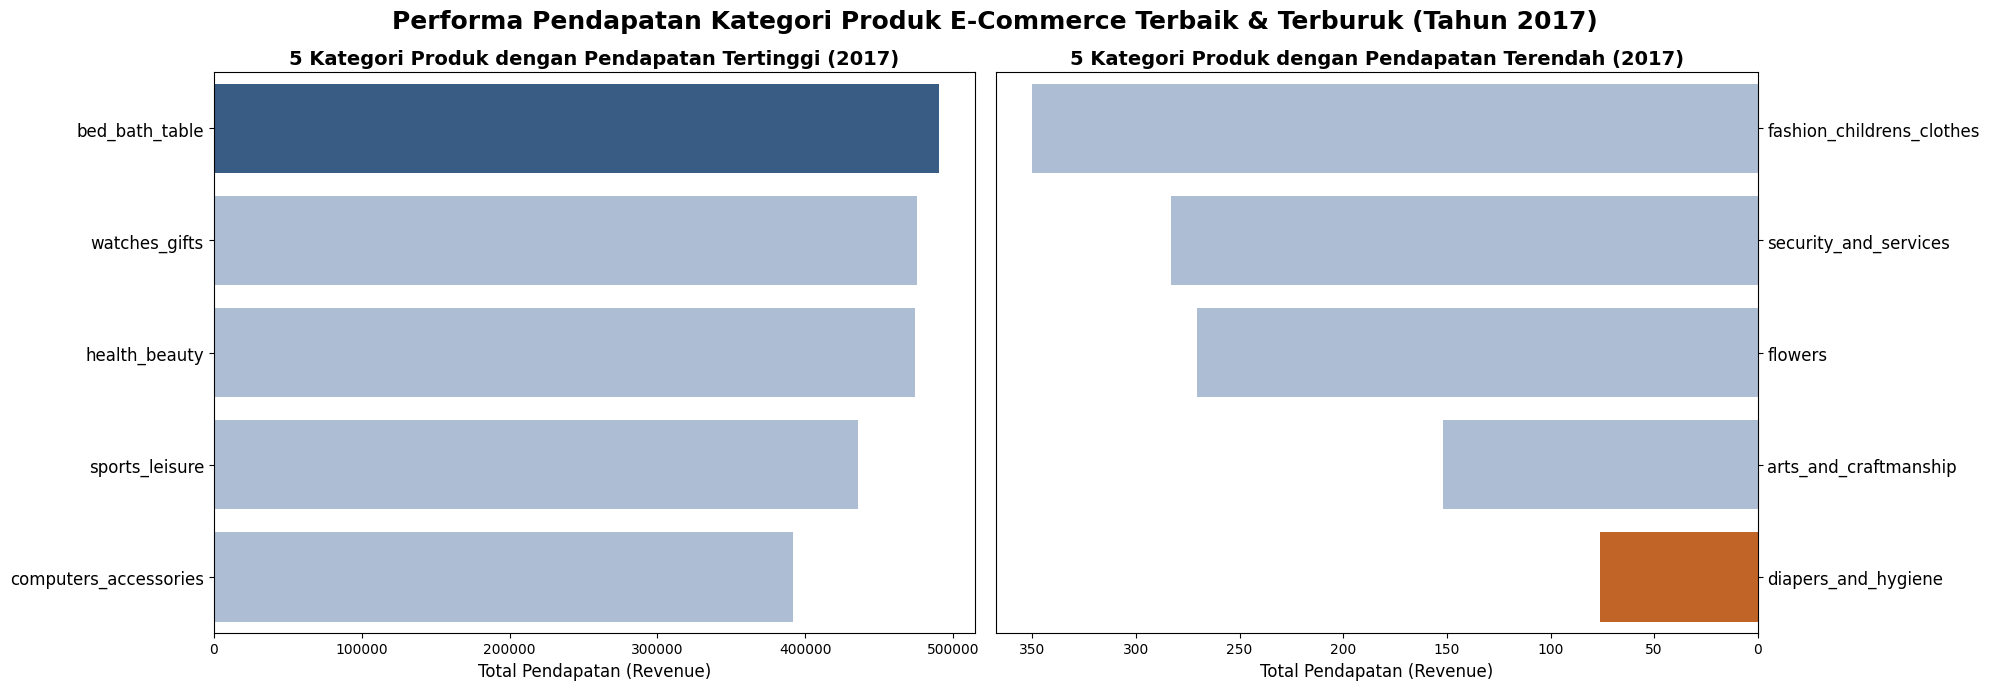

In [22]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(20, 7))

colors_top = ["#2b5c8f", "#a6bddb", "#a6bddb", "#a6bddb", "#a6bddb"]
colors_bottom = ["#a6bddb", "#a6bddb", "#a6bddb", "#a6bddb", "#d95f0e"]

# Grafik Kiri: Top 5 Kategori Pendapatan Tertinggi
sns.barplot(
    x="total_revenue",
    y="category",
    data=category_revenue_2017.head(5),
    palette=colors_top,
    hue="category",
    legend=False,
    ax=ax[0]
)
ax[0].set_ylabel(None)
ax[0].set_xlabel("Total Pendapatan (Revenue)", fontsize=12)
ax[0].set_title("5 Kategori Produk dengan Pendapatan Tertinggi (2017)", loc="center", fontsize=14, fontweight="bold")
ax[0].tick_params(axis='y', labelsize=12)

# Grafik Kanan: Bottom 5 Kategori Pendapatan Terendah
sns.barplot(
    x="total_revenue",
    y="category",
    data=category_revenue_2017.tail(5),
    palette=colors_bottom,
    hue="category",
    legend=False,
    ax=ax[1]
)
ax[1].set_ylabel(None)
ax[1].set_xlabel("Total Pendapatan (Revenue)", fontsize=12)
ax[1].invert_xaxis()
ax[1].yaxis.set_label_position("right")
ax[1].yaxis.tick_right()
ax[1].set_title("5 Kategori Produk dengan Pendapatan Terendah (2017)", loc="center", fontsize=14, fontweight="bold")
ax[1].tick_params(axis='y', labelsize=12)

plt.suptitle("Performa Pendapatan Kategori Produk E-Commerce Terbaik & Terburuk (Tahun 2017)", fontsize=18, fontweight="bold")
plt.tight_layout()
plt.show()

### Pertanyaan 2:

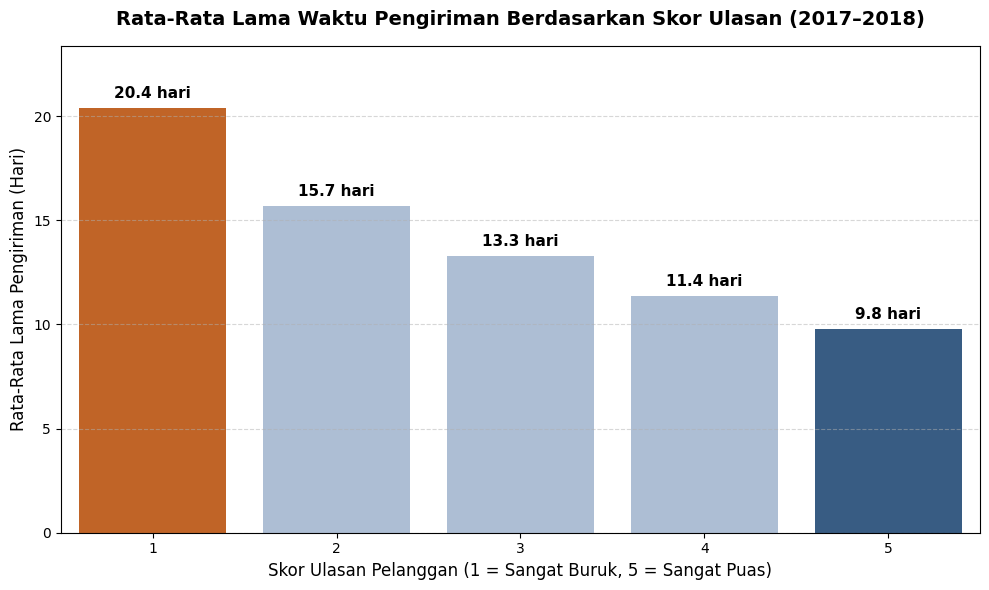

In [23]:
# Menyiapkan data rata-rata lama pengiriman per skor ulasan
avg_delivery_df = orders_reviews_df.groupby("review_score")["delivery_days"].mean().reset_index()

plt.figure(figsize=(10, 6))
colors_review = ["#d95f0e" if score == 1 else ("#2b5c8f" if score == 5 else "#a6bddb") for score in avg_delivery_df["review_score"]]

ax = sns.barplot(
    x="review_score",
    y="delivery_days",
    data=avg_delivery_df,
    palette=colors_review,
    hue="review_score",
    legend=False
)

# Menambahkan label angka di atas setiap batang
for p in ax.patches:
    ax.annotate(
        f"{p.get_height():.1f} hari",
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha="center", va="bottom",
        fontsize=11, fontweight="bold", xytext=(0, 5), textcoords="offset points"
    )

plt.title("Rata-Rata Lama Waktu Pengiriman Berdasarkan Skor Ulasan (2017–2018)", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Skor Ulasan Pelanggan (1 = Sangat Buruk, 5 = Sangat Puas)", fontsize=12)
plt.ylabel("Rata-Rata Lama Pengiriman (Hari)", fontsize=12)
plt.ylim(0, avg_delivery_df["delivery_days"].max() + 3)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [24]:
# Menggabungkan data lengkap untuk kebutuhan dashboard Streamlit
all_df = pd.merge(
    left=full_products_orders_df,
    right=reviews_df[['order_id', 'review_score']],
    how='left',
    on='order_id'
)
all_df['delivery_days'] = (all_df['order_delivered_customer_date'] - all_df['order_approved_at']).dt.days
all_df = all_df[all_df['delivery_days'] >= 0]

# Menyimpan ke file CSV
all_df.to_csv("all_df.csv", index=False)
print("File all_df.csv berhasil disimpan! Total baris:", len(all_df))

File all_df.csv berhasil disimpan! Total baris: 109210


**Insight:** (Opsional)
- **Visualisasi Pertanyaan 1 (Performa Pendapatan Kategori Produk 2017):**
  - Grafik batang horizontal menunjukkan kesenjangan pendapatan yang sangat lebar antara kategori teratas dan terbawah. Kategori **bed_bath_table** memimpin perolehan pendapatan (hampir menyentuh angka 500.000), diikuti rapat oleh **watches_gifts** dan **health_beauty** di atas angka 470.000.
  - Sebaliknya, pada kelompok 5 kategori terendah, seluruhnya mencatatkan pendapatan di bawah 350, dengan **diapers_and_hygiene** berada di posisi paling dasar (di bawah 100).
- **Visualisasi Pertanyaan 2 (Rata-Rata Lama Pengiriman vs Skor Ulasan 2017–2018):**
  - Grafik batang memperlihatkan tren penurunan durasi pengiriman yang bertahap dan konsisten dari skor terendah hingga tertinggi.
  - Pelanggan yang memberikan **skor 1** mengalami rata-rata waktu tunggu pengiriman terlama hingga **20,4 hari**, sedangkan pelanggan yang memberikan **skor 5** menerima pesanan mereka dalam waktu rata-rata jauh lebih cepat, yakni **9,8 hari** (selisih lebih dari 10 hari).

## Analisis Lanjutan (Opsional)

In [25]:
# Mengelompokkan durasi pengiriman (Binning)
def categorize_delivery(days):
    if days <= 7:
        return "1. Cepat (<= 7 hari)"
    elif days <= 14:
        return "2. Sedang (8 - 14 hari)"
    else:
        return "3. Lambat (> 14 hari)"

orders_reviews_df['delivery_speed'] = orders_reviews_df['delivery_days'].apply(categorize_delivery)

# Melihat jumlah pesanan dan rata-rata skor ulasan per kategori kecepatan
speed_summary = orders_reviews_df.groupby('delivery_speed').agg(
    total_orders=('order_id', 'count'),
    avg_review_score=('review_score', 'mean')
).reset_index()

print(speed_summary)

            delivery_speed  total_orders  avg_review_score
0     1. Cepat (<= 7 hari)         36609          4.401732
1  2. Sedang (8 - 14 hari)         34660          4.279631
2    3. Lambat (> 14 hari)         24218          3.607606


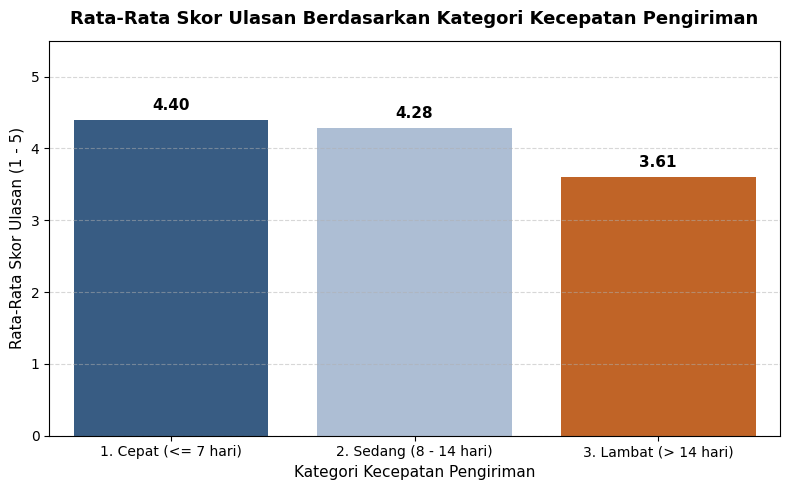

In [26]:
# Visualisasi Analisis Lanjutan: Rata-rata Skor Ulasan berdasarkan Kecepatan Pengiriman
plt.figure(figsize=(8, 5))
colors_speed = ["#2b5c8f", "#a6bddb", "#d95f0e"]

ax = sns.barplot(
    x="delivery_speed",
    y="avg_review_score",
    data=speed_summary,
    palette=colors_speed,
    hue="delivery_speed",
    legend=False
)

# Menambahkan label angka tepat di atas setiap batang
for p in ax.patches:
    ax.annotate(
        f"{p.get_height():.2f}",
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha="center", va="bottom",
        fontsize=11, fontweight="bold", xytext=(0, 5), textcoords="offset points"
    )

plt.title("Rata-Rata Skor Ulasan Berdasarkan Kategori Kecepatan Pengiriman", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Kategori Kecepatan Pengiriman", fontsize=11)
plt.ylabel("Rata-Rata Skor Ulasan (1 - 5)", fontsize=11)
plt.ylim(0, 5.5)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Pengelompokan (*binning*) durasi pengiriman memperjelas titik kritis kepuasan pelanggan: pesanan pada kategori **1. Cepat (<= 7 hari)** (36.609 pesanan) mencatatkan rata-rata skor ulasan tertinggi sebesar **4,40**, dan kategori **2. Sedang (8 - 14 hari)** (34.660 pesanan) masih mempertahankan skor yang sangat baik di angka **4,28**.
- Namun, ketika pengiriman melewati batas 14 hari (**3. Lambat (> 14 hari)** sebanyak 24.218 pesanan), rata-rata skor ulasan turun drastis menjadi **3,61**. Hal ini menegaskan bahwa **14 hari** adalah indikasi batas operasional waktu pengiriman sebelum kepuasan pelanggan merosot tajam.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Sepanjang tahun 2017, kategori produk yang menyumbang total pendapatan (*revenue*) tertinggi adalah **bed_bath_table** (490.462,93), diikuti oleh **watches_gifts** (475.610,71) dan **health_beauty** (473.833,00). Sementara itu, kategori produk dengan kontribusi pendapatan terendah adalah **diapers_and_hygiene** (76,00), **arts_and_craftmanship** (151,89), dan **flowers** (270,50).
- **Conclusion pertanyaan 2:** Lama waktu pengiriman menunjukkan hubungan negatif moderat terhadap kepuasan pelanggan selama periode 2017–2018 (korelasi -0,33). Semakin lama durasi pengiriman paket hingga diterima pelanggan, semakin rendah skor ulasan yang diberikan—tercermin dari rata-rata pengiriman **20,4 hari** pada pesanan berskor 1 dibandingkan **9,8 hari** pada pesanan berskor 5.

**Rekomendasi Action Item:**
- **Optimalisasi Pemasaran & Stok Kategori Unggulan:** Alokasikan anggaran promosi, kampanye *bundling*, dan prioritas ketersediaan stok pada 5 kategori penyumbang pendapatan tertinggi (`bed_bath_table`, `watches_gifts`, `health_beauty`, `sports_leisure`, dan `computers_accessories`) untuk memaksimalkan perolehan *revenue*. Untuk kategori terbawah seperti `diapers_and_hygiene`, lakukan evaluasi apakah rendahnya penjualan disebabkan oleh kurangnya eksposur atau memang bukan fokus pasar utama platform.
- **Perketat SLA Mitra Logistik:** Tetapkan batas waktu pengiriman maksimal (*Service Level Agreement*) di bawah 10–11 hari untuk menjaga kepuasan pelanggan di rentang skor 4–5. Berikan peringatan dini atau notifikasi otomatis kepada tim operasional maupun pelanggan apabila status pengiriman berpotensi melewati hari ke-14 guna menekan risiko ulasan bintang 1.